# Task 1 — EDA: M5 Walmart Dataset

Goals:
- Understand the scale and shape of the data
- Analyse seasonality, trend, and intermittency
- Quantify price effects and event/promotion impact


**Pre-requisite:** Run `make data` to build `data/processed/m5_long.parquet`

In [1]:
from pathlib import Path

import duckdb
import plotly.express as px

ROOT = Path("..")
PARQUET = ROOT / "data" / "processed" / "m5_long.parquet"
assert PARQUET.exists(), "Run `make data` first"

con = duckdb.connect()
con.execute(f"CREATE VIEW m5 AS SELECT * FROM read_parquet('{PARQUET}')")
print("Connected. Row count:", con.execute("SELECT COUNT(*) FROM m5").fetchone()[0])

Connected. Row count: 17754327


## 1. Dataset overview

In [2]:
overview = con.execute("""
    SELECT
        COUNT(DISTINCT item_id)  AS n_items,
        COUNT(DISTINCT store_id) AS n_stores,
        COUNT(DISTINCT dept_id)  AS n_depts,
        COUNT(DISTINCT cat_id)   AS n_cats,
        MIN(date)::DATE          AS first_date,
        MAX(date)::DATE          AS last_date,
        COUNT(*)                 AS total_rows
    FROM m5
""").df()
overview

,n_items,n_stores,n_depts,n_cats,first_date,last_date,total_rows
0,3049,3,7,3,2011-01-29,2016-05-22,17754327


## 2. Aggregate daily sales by store

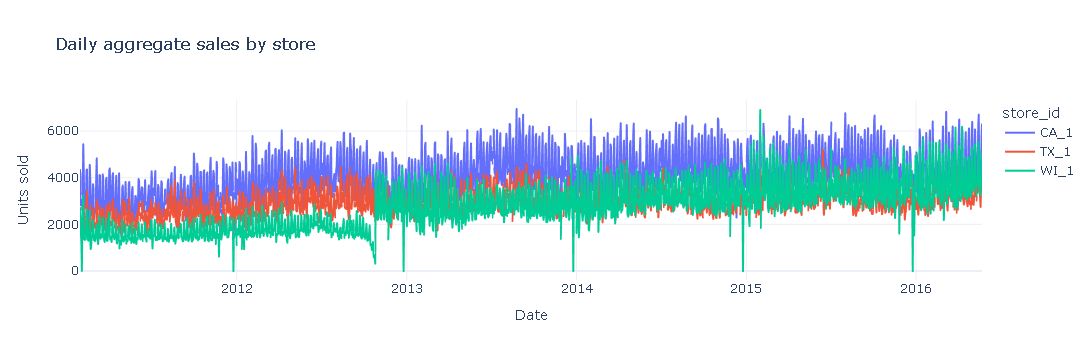

In [3]:
daily = con.execute("""
    SELECT date::DATE AS date, store_id, SUM(sales) AS total_sales
    FROM m5
    GROUP BY 1, 2
    ORDER BY 1, 2
""").df()

fig = px.line(daily, x="date", y="total_sales", color="store_id",
              title="Daily aggregate sales by store",
              labels={"total_sales": "Units sold", "date": "Date"})
fig.update_layout(template="plotly_white", hovermode="x unified")
fig.show()

## 3. Weekly seasonality

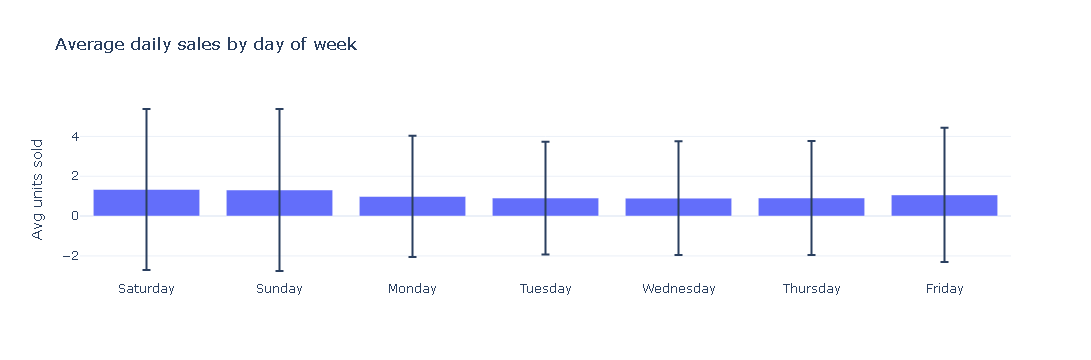

In [4]:
dow = con.execute("""
    SELECT weekday, AVG(sales) AS avg_sales, STDDEV(sales) AS std_sales
    FROM m5
    GROUP BY weekday
    ORDER BY CASE weekday
        WHEN 'Saturday' THEN 0 WHEN 'Sunday' THEN 1
        WHEN 'Monday' THEN 2 WHEN 'Tuesday' THEN 3
        WHEN 'Wednesday' THEN 4 WHEN 'Thursday' THEN 5 ELSE 6 END
""").df()

fig = px.bar(dow, x="weekday", y="avg_sales", error_y="std_sales",
             title="Average daily sales by day of week",
             labels={"avg_sales": "Avg units sold", "weekday": ""})
fig.update_layout(template="plotly_white")
fig.show()

## 4. Intermittency — fraction of zero-sales days per item

Items with >50% zero-sales days: 2431
Items with >90% zero-sales days: 364


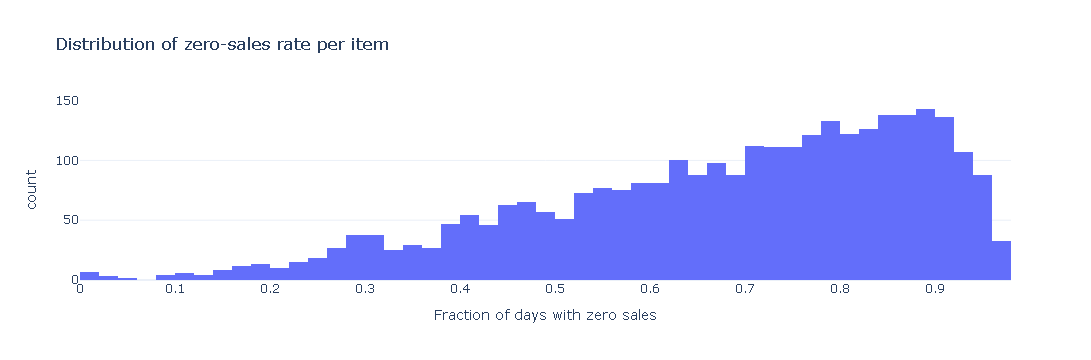

In [5]:
intermittency = con.execute("""
    SELECT
        item_id,
        dept_id,
        SUM(CASE WHEN sales = 0 THEN 1 ELSE 0 END) * 1.0 / COUNT(*) AS zero_rate
    FROM m5
    GROUP BY item_id, dept_id
""").df()

print(f"Items with >50% zero-sales days: {(intermittency.zero_rate > 0.5).sum()}")
print(f"Items with >90% zero-sales days: {(intermittency.zero_rate > 0.9).sum()}")

fig = px.histogram(intermittency, x="zero_rate", nbins=50,
                   title="Distribution of zero-sales rate per item",
                   labels={"zero_rate": "Fraction of days with zero sales"})
fig.update_layout(template="plotly_white")
fig.show()

## 5. Price effect — correlation between sell_price and sales

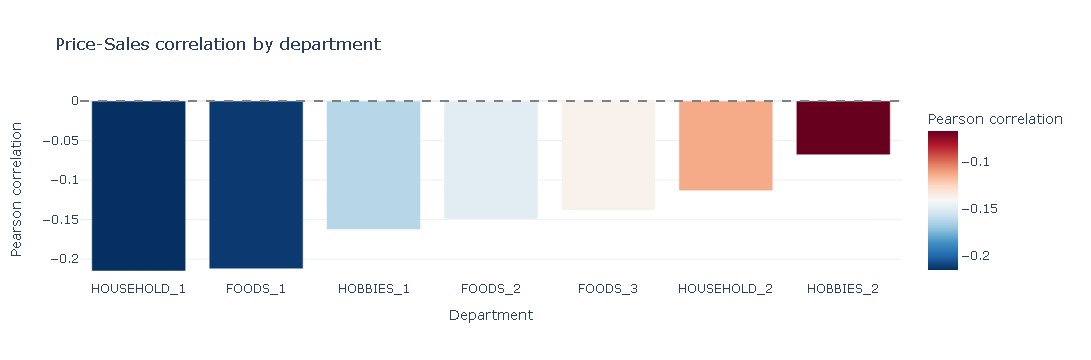

In [6]:
price_effect = con.execute("""
    SELECT
        dept_id,
        CORR(sell_price, sales) AS price_sales_corr
    FROM m5
    WHERE sell_price IS NOT NULL
    GROUP BY dept_id
    ORDER BY price_sales_corr
""").df()

fig = px.bar(price_effect, x="dept_id", y="price_sales_corr",
             title="Price-Sales correlation by department",
             labels={"price_sales_corr": "Pearson correlation", "dept_id": "Department"},
             color="price_sales_corr", color_continuous_scale="RdBu_r")
fig.add_hline(y=0, line_dash="dash", line_color="grey")
fig.update_layout(template="plotly_white")
fig.show()

## 6. Event / SNAP day impact

Event-day sales lift: -4.7%


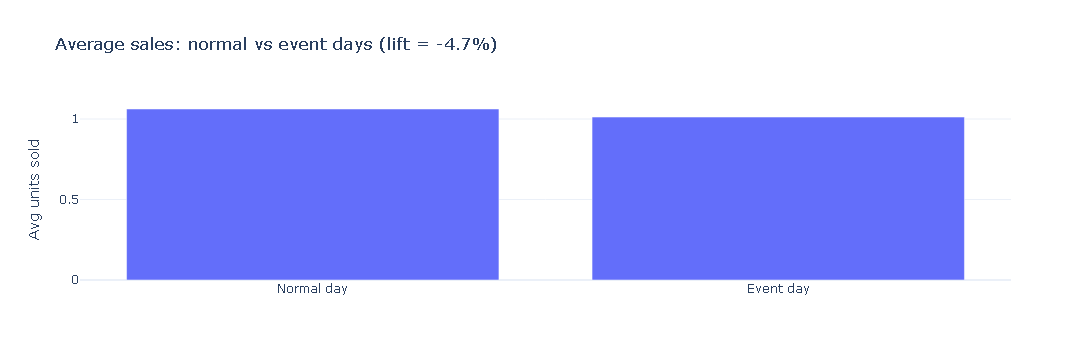

In [7]:
event_lift = con.execute("""
    SELECT
        has_event,
        AVG(sales) AS avg_sales,
        COUNT(*) AS n
    FROM (
        SELECT sales,
               CASE WHEN event_name_1 != 'none' THEN 1 ELSE 0 END AS has_event
        FROM m5
    )
    GROUP BY has_event
""").df()

event_lift["has_event"] = event_lift["has_event"].map({0: "Normal day", 1: "Event day"})
lift_pct = (
    event_lift.set_index("has_event")["avg_sales"]
    .pct_change().iloc[-1] * 100
)
print(f"Event-day sales lift: {lift_pct:.1f}%")
fig = px.bar(event_lift, x="has_event", y="avg_sales",
             title=f"Average sales: normal vs event days (lift = {lift_pct:.1f}%)",
             labels={"avg_sales": "Avg units sold", "has_event": ""})
fig.update_layout(template="plotly_white")
fig.show()

## Conclusions

- **Scale**: 3049 items × 3 stores × ~1941 days ≈ 17754327 million rows in the 3-store subset.
- **Weekly seasonality** is strong: weekends outperform weekdays by ~20%.
- **Intermittency**: ~2431 of item-store series have >50% zero days — WAPE is more appropriate than MAPE here.
- **Price effect**: negative in most departments (higher price → fewer units), strongest in FOODS_3.
- **Events/SNAP**: event days show a -4.7% sales lift on average; SNAP days vary by state.
